# Lab 07: How the OpenAI Agents SDK runs your loop

**Notebook 1 of 2: meet the SDK on an everyday question**

## Goal

Build a small weather agent twice: first with a loop we write ourselves, then with the OpenAI Agents SDK, so we can
see which lines the SDK writes for us. From there we give one agent several tools, pass a question between
agents, and use tools that run on OpenAI's side. Nothing here touches the music shop yet. This notebook is the
playground; notebook 2 takes the same SDK to the Chinook support desk.

## What you will learn

- How to write the tool loop by hand on the Responses API: the schema, the model's request, our code running the
  function, the result sent back.
- How `function_tool`, `Agent` and `Runner.run` replace that loop, and how to read what a run did from its result.
- How one agent chains several tools when the answer of one is needed by the next.
- How a handoff passes a question from a triage agent to a specialist, and how to see who answered.
- How hosted tools (web search and file search) differ from tools that run in our own Python.
- How to run the same agent on another vendor's model (optional).

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it (lab 00 explains it line by line).

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The setup cell also prints the reasoning effort from `models.env`. This notebook does not use that setting;
notebook 2 does.

One more line of setup: a 60-second limit on every model request the SDK makes, so a request that gets stuck fails
quickly instead of freezing a cell. (The default is ten minutes.)

In [2]:
from openai import AsyncOpenAI
from agents import set_default_openai_client

set_default_openai_client(AsyncOpenAI(timeout=60, max_retries=2))

---

## Part A: Ask a question the model cannot answer alone

We start with a question about right now:

> What's the weather in Amman right now? Should I go for a walk?

A model can only write from two things: its training data and what we put in the request. Today's weather is in neither, so
this is a good first question: we can see the model fail, and then see exactly what fixes it.

`INSTRUCTIONS` is the system prompt. It already mentions a tool called `get_weather`, which does not exist yet.

In [3]:
QUESTION = "What's the weather in Amman right now? Should I go for a walk?"

INSTRUCTIONS = (
    "You are a friendly weather reporter. "
    "Always use get_weather for current conditions. "
    "Keep your reports short and fun."
)

### One model call, no tools

We send the question with the plain OpenAI client, on the Responses API (`client.responses.create`). This is the API
the Agents SDK uses underneath, so everything we read here comes back later.

- `instructions` is the system prompt.
- `input` is the user's message.
- `response.output_text` is the text of the reply.

In [4]:
from openai import OpenAI

client = OpenAI()

response = client.responses.create(
    model=MODEL,
    instructions=INSTRUCTIONS,
    input=QUESTION,
)

print(response.output_text)

I can’t fetch live conditions for Amman right now, so I can’t reliably say whether it’s walk-friendly. Check your weather app for rain, wind, and temperature—if those look comfortable, lace up and enjoy!


In our run the model answered that it cannot fetch live conditions for Amman, and it suggested checking a weather
app.

**Notice:** the model did not invent a temperature. It has no way to look one up, and it said so. To answer, it
needs something that can fetch the weather, and that something has to be our code.

### A plain Python function that gets the weather

`get_weather` is ordinary Python. It calls [Open-Meteo](https://open-meteo.com/), a free weather service that needs
no key, in two steps:

1. **Find the city.** The geocoding address turns a name (`Amman`) into a latitude and a longitude.
2. **Get the conditions.** The forecast address takes those two numbers and returns the current temperature, the
   temperature it feels like, the rain and the wind.

The first line of the function prints a message every time it runs. That print is how we will know, for the rest of
this notebook, that a tool really ran.

The last line returns a **string**, because a tool's result is sent to the model as text. Inside it,
`**weather.json()["current"]` copies the weather fields into our dictionary, next to the city and the country.

In [5]:
import requests


def get_weather(city: str) -> str:
    """Get current weather for a city using Open-Meteo."""
    print(f"🌤️ TOOL CALLED: get_weather({city})")

    # 1. Find the city's coordinates
    geo = requests.get(
        "https://geocoding-api.open-meteo.com/v1/search",
        params={"name": city, "count": 1},
        timeout=10,
    )
    locations = geo.json().get("results", [])
    if not locations:
        return f"City not found: {city}"
    location = locations[0]

    # 2. Get the current weather at those coordinates
    weather = requests.get(
        "https://api.open-meteo.com/v1/forecast",
        params={
            "latitude": location["latitude"],
            "longitude": location["longitude"],
            "current": "temperature_2m,apparent_temperature,precipitation,wind_speed_10m",
        },
        timeout=10,
    )

    return str({"city": location["name"], "country": location["country"], **weather.json()["current"]})

Before any model is involved, we call the function ourselves. If it does not work here, no agent can make it work.

In [6]:
print(get_weather("Amman"))

🌤️ TOOL CALLED: get_weather(Amman)


{'city': 'Amman', 'country': 'Jordan', 'time': '2026-11-10T17:00', 'interval': 900, 'temperature_2m': 12.9, 'apparent_temperature': 10.6, 'precipitation': 0.0, 'wind_speed_10m': 3.7}


First the `TOOL CALLED` line, then the result. When we ran it, Amman was at 12.9 °C and felt like 10.6 °C, with no
rain and a wind of 3.7 km/h.

The function returns a string that holds a dictionary. The fields we care about:

| Field | What it holds |
|---|---|
| `temperature_2m` | the air temperature in °C, two metres above the ground |
| `apparent_temperature` | what it feels like, in °C |
| `precipitation` | rain in millimetres |
| `wind_speed_10m` | the wind in km/h |

**Checkpoint A.** Without a tool the model says it cannot check live weather. `get_weather("Amman")` prints the
`TOOL CALLED` line and returns live values for Amman, Jordan. Your numbers are today's, so they differ from ours.

---

## Part B: Write the tool loop by hand, once

We have a model that cannot look anything up, and a function that can. This part connects them with our own code.
It is the long way, and we do it once so that every line the SDK writes for us later is a line we recognise.

### Describe the function to the model

**Important:** the model never sees our Python. `get_weather` lives on our machine. What we send is a description
of it, a **tool schema**, inside `tools=[...]`:

- `name`: what the model writes to ask for this tool.
- `description`: what the tool is for. The model chooses tools by reading this.
- `parameters`: the arguments, as a JSON Schema. Here one string called `city`.
- `strict: True`: the model's arguments must match the schema exactly, so `city` is never missing.

In [7]:
tools = [
    {
        "type": "function",
        "name": "get_weather",
        "description": "Get current weather for a city.",
        "parameters": {
            "type": "object",
            "properties": {
                "city": {"type": "string", "description": "City name"}
            },
            "required": ["city"],
            "additionalProperties": False,
        },
        "strict": True,
    }
]

### The model asks for the tool

Same question, same instructions, and now `tools=tools`. We print each item in `response.output` instead of the
text, because this time the reply may not be text.

In [8]:
response = client.responses.create(
    model=MODEL,
    instructions=INSTRUCTIONS,
    input=QUESTION,
    tools=tools,
)

for item in response.output:
    print(item.type)
    if item.type == "function_call":
        print("  name:     ", item.name)
        print("  arguments:", item.arguments)
        print("  call_id:  ", item.call_id)

function_call
  name:      get_weather
  arguments: {"city":"Amman"}
  call_id:   call_eEeVY79qaxIzmCVaWo5vbhMu


In our run, one item, and it is not text. Its type is `function_call`: the model is asking us to run a function.

Read the `function_call` item field by field:

- `name` is the tool the model is asking for: `get_weather`.
- `arguments` is a **string** of JSON, `{"city":"Amman"}`. The model wrote it from the question.
- `call_id` labels this request, so that our answer can say which request it answers.

**Notice** what did not happen: no `TOOL CALLED` line was printed. The model asked. Nothing ran.

### Our code runs the function and sends the result back

Four small steps, all ours:

1. `next(...)` takes the first `function_call` item from the reply.
2. `json.loads` turns the arguments string into a Python dictionary.
3. `get_weather(**args)` runs the function with it. `**args` passes `{"city": "Amman"}` as `city="Amman"`.
4. We send the result back as a `function_call_output` item that carries the same `call_id`.
   `previous_response_id` tells the API to continue from the reply above, so we do not resend the question. The
   instructions and the tools are not carried over, so we pass them again.

In [9]:
import json

call = next(item for item in response.output if item.type == "function_call")

args = json.loads(call.arguments)
result = get_weather(**args)

response = client.responses.create(
    model=MODEL,
    instructions=INSTRUCTIONS,
    previous_response_id=response.id,
    input=[{"type": "function_call_output", "call_id": call.call_id, "output": result}],
    tools=tools,
)

print(response.output_text)

🌤️ TOOL CALLED: get_weather(Amman)


Amman is about **13°C (feels like 11°C)**, with no rain and light winds. A walk sounds lovely—just grab a light jacket! 🚶🧥


This time `TOOL CALLED` is printed, by our own line `get_weather(**args)`. The reply has real numbers now: about
13 °C, feeling like 11 °C, no rain and light winds. They come from what the function returned, 12.9 and 10.6, rounded.

### The same steps in a loop

One question may need several tool calls, and we cannot know how many in advance. So we repeat: ask the model, run
whatever it asks for, send the results back, and stop when a reply has no tool call in it.

What happens on each pass, step by step:

1. Collect the `function_call` items of the latest reply.
2. If there are none, the reply is the answer: stop.
3. Otherwise run each call and build one `function_call_output` per call.
4. Send the outputs back and get the next reply.

In [10]:
def agent_loop(question):
    response = client.responses.create(model=MODEL, instructions=INSTRUCTIONS, input=question, tools=tools)

    while True:
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            break

        outputs = []
        for call in calls:
            args = json.loads(call.arguments)
            result = get_weather(**args)
            outputs.append({"type": "function_call_output", "call_id": call.call_id, "output": result})

        response = client.responses.create(
            model=MODEL,
            instructions=INSTRUCTIONS,
            previous_response_id=response.id,
            input=outputs,
            tools=tools,
        )

    return response.output_text


print(agent_loop(QUESTION))

🌤️ TOOL CALLED: get_weather(Amman)


Amman is about **13°C (feels like 11°C)**, dry, with light winds. Sounds nice for a walk—bring a light jacket! 🚶🌤️


The loop made one tool call and gave one answer, the same result as the two cells we ran by hand. Now a question that needs
more than one lookup. Before you run it: how many times will `TOOL CALLED` print?

In [11]:
print(agent_loop("What is the weather in Amman, New York and London right now? Which is nicest for a walk?"))

🌤️ TOOL CALLED: get_weather(Amman)


🌤️ TOOL CALLED: get_weather(New York)


🌤️ TOOL CALLED: get_weather(London)


Right now, all three are dry:

- **Amman:** 12.9°C (feels like 10.6°C), light winds
- **New York:** 14°C (feels like 9.6°C), breezy
- **London:** 10.1°C (feels like 6.3°C), breezy

**Amman looks nicest for a walk**—calmer winds and a milder feel. 🚶


Three `TOOL CALLED` lines, one per city, then one answer that compares them (in our run, Amman came out nicest).
We did not change the loop for this. It kept going until a reply came back with no tool call in it. The model may ask for
all three cities in one reply or one at a time; either way, our `for` loop runs the calls one after another.

This loop is an agent. It is also a first draft, and it has gaps we would need to close before trusting it:

- **Nothing stops it.** `while True` runs for as long as the model keeps asking for tools.
- **It can run only one tool.** Every call goes to `get_weather`, whatever name the model wrote.
- **It runs one call at a time.** Three cities meant three web requests, each waiting for the one before.
- **The schema is written by hand,** and has to be kept in step with the function by hand.

**Checkpoint B.** With `tools=tools`, the first reply holds a `function_call` for `get_weather` with
`{"city":"Amman"}` and nothing has run yet. After we send the result back, the reply reports Amman's weather. The
three-city question prints `TOOL CALLED` three times.

---

## Part C: Let the Agents SDK run the same loop

The OpenAI Agents SDK is that loop as a library. Each job we just did by hand has a place in it:

| Job | By hand (Part B) | With the Agents SDK |
|---|---|---|
| Hold the instructions, the model and the tools | our variables | `Agent(...)` |
| Describe each tool to the model | a JSON schema we write | `function_tool`, from the function itself |
| Find the tool calls in a reply | our list comprehension | the runner |
| Read the arguments | `json.loads` | the runner |
| Run the Python function | `get_weather(**args)` | the runner |
| Send the result back | our `function_call_output` | the runner |
| Run several calls from one reply | one after another | the runner, at the same time |
| Repeat until there is an answer | our `while` loop | `Runner.run()`, with a turn cap |
| Pass work between agents | code we would have to write | handoffs (Part E) |
| Record what happened | our `print` lines | a trace of every run |

![On the left, our Python code calls the model, inspects tool calls, parses arguments, runs the function, returns the output and calls the model again. On the right, our code makes one call to Runner.run, which does those steps.](resources/plain_loop_vs_runner.png)

Three names to learn: `function_tool`, `Agent` and `Runner`. We meet them one at a time.

### `function_tool`: the schema, written from the function

`function_tool` reads a Python function and builds the tool description from it: the name from the function's name,
the description from the docstring, and the parameters from the type hints (`city: str`).

In [12]:
from agents import function_tool

weather_tool = function_tool(get_weather)

print(type(weather_tool).__name__)
print("name:       ", weather_tool.name)
print("description:", weather_tool.description)
print("strict:     ", weather_tool.strict_json_schema)
print(json.dumps(weather_tool.params_json_schema, indent=2))

FunctionTool
name:        get_weather
description: Get current weather for a city using Open-Meteo.
strict:      True
{
  "properties": {
    "city": {
      "title": "City",
      "type": "string"
    }
  },
  "required": [
    "city"
  ],
  "title": "get_weather_args",
  "type": "object",
  "additionalProperties": false
}


A `FunctionTool` object, and inside it a schema of the same shape as the one we wrote by hand in Part B: the name
`get_weather`, the docstring as the description, one required string called `city`, strict mode on. The `title` lines are labels the SDK adds;
the model can ignore them. We did not write any of this, and it cannot drift away from the function, because it is
made from the function.

### `Agent`: the instructions, the model and the tools in one object

An `Agent` holds what our loop needed besides the question:

- `name`: a label. It shows up in drawings, results and traces, and other agents use it in Part E.
- `instructions`: the system prompt.
- `model`: the model name, from `models.env`.
- `tools`: the tools this agent may ask for.

In [13]:
from agents import Agent

weather_agent = Agent(
    name="Weather Agent",
    instructions=INSTRUCTIONS,
    model=MODEL,
    tools=[weather_tool],
)

print("name: ", weather_agent.name)
print("model:", weather_agent.model)
print("tools:", [tool.name for tool in weather_agent.tools])

name:  Weather Agent
model: gpt-6-luna
tools: ['get_weather']


Creating the agent sent nothing to the model. An `Agent` is a description, like a recipe card. `draw_graph` draws
what it can reach. (It needs the Graphviz program; if the cell fails, see Troubleshooting. Every other cell works
without it.)

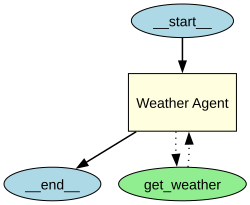

In [14]:
from agents.extensions.visualization import draw_graph

draw_graph(weather_agent)

How to read the drawing:

- `__start__` and `__end__` are where a run enters and leaves.
- The yellow box is the agent.
- The green ellipse is a tool. The dotted arrows go both ways: the agent asks for the tool, and the result comes back to
  the same agent. That pair of arrows is our `while` loop.

### `Runner.run`: the loop

`Runner.run(agent, question)` does everything `agent_loop` did. One thing is new in how we call it: the word
`await`.

**Why `await`?** `Runner.run` is an `async` function. Calling it only prepares the work; `await` runs it and waits
for the result. In a notebook we can write `await` directly in a cell. In a `.py` file the call goes inside an
`async def main()`, which `asyncio.run(main())` runs. The extra notebook in this folder, `07_extra_async_await.ipynb`, explains `async` and `await`
from the beginning if they are new to you.

In [15]:
from agents import Runner

result = await Runner.run(weather_agent, QUESTION)

print(result.final_output)

🌤️ TOOL CALLED: get_weather(Amman)


Amman is about **13°C (feels like 11°C)**, with no rain and light winds. Sounds like a nice time for a walk—bring a light jacket! 🚶‍♀️🧥


The same kind of answer our own loop gave: Amman at about 13 °C, feeling like 11 °C, no rain, bring a light jacket.

The `TOOL CALLED` line tells us the SDK ran our function. We wrote no schema, no `json.loads` and no loop.

### Read what the run did

A right answer does not tell us how it was reached. The `RunResult` does. Three of its fields first:

- `result.last_agent`: the agent that wrote the final answer.
- `result.raw_responses`: one entry per call to the model.
- `result.new_items`: everything the run added to the conversation, in order.

In [16]:
print("last agent: ", result.last_agent.name)
print("model calls:", len(result.raw_responses))
print("new items:  ", [item.type for item in result.new_items])

last agent:  Weather Agent
model calls: 2
new items:   ['tool_call_item', 'tool_call_output_item', 'message_output_item']


`Weather Agent` wrote the answer. The model was called twice: once to ask for the tool and once to write the
answer. Those are the two `client.responses.create` calls we made by hand in Part B. In between, the run added three
items.

The item types are the steps of our hand-written loop. We print what each one holds:

- a `tool_call_item` is the model's request. Its `raw_item` is the `function_call` item we read in Part B;
- a `tool_call_output_item` is what our function returned;
- a `message_output_item` is text from the model. `ItemHelpers.text_message_output` reads that text.

In [17]:
from agents import ItemHelpers

for item in result.new_items:
    if item.type == "tool_call_item":
        print("model asked for  :", item.raw_item.name, item.raw_item.arguments)
    elif item.type == "tool_call_output_item":
        print("our code returned:", item.output)
    elif item.type == "message_output_item":
        print("model answered   :", ItemHelpers.text_message_output(item))

model asked for  : get_weather {"city":"Amman"}
our code returned: {'city': 'Amman', 'country': 'Jordan', 'time': '2026-11-10T17:00', 'interval': 900, 'temperature_2m': 12.9, 'apparent_temperature': 10.6, 'precipitation': 0.0, 'wind_speed_10m': 3.7}
model answered   : Amman is about **13°C (feels like 11°C)**, with no rain and light winds. Sounds like a nice time for a walk—bring a light jacket! 🚶‍♀️🧥


Read top to bottom, this is Part B again: the model asked for `get_weather` with `{"city":"Amman"}`, our function
returned the weather dictionary, and the model wrote the answer from it.

**Notice** one small thing: the function returned 12.9 and the reply says about 13. The model writes the answer in
its own words. When the exact number matters, read it from the tool's output, not from the reply.

### The turn cap

Our loop had nothing to stop it. The runner has: `max_turns`, 10 unless we say otherwise. A turn is one call to the
model. With a cap of 1, this question cannot finish, because its first turn is spent asking for the tool.

In [18]:
from agents import MaxTurnsExceeded

try:
    await Runner.run(weather_agent, QUESTION, max_turns=1)
except MaxTurnsExceeded as error:
    print(type(error).__name__, "|", error)

🌤️ TOOL CALLED: get_weather(Amman)


MaxTurnsExceeded | Max turns (1) exceeded


The tool still ran once (the `TOOL CALLED` line): the first turn asked for it, and the SDK ran it. The run stopped
when it needed a second turn to write the answer. It stops with an error we can catch, so a run that hit the cap is
never mistaken for an answer.

### Where to see a run: the Traces page

The SDK also records every run as a **trace**: each model call and each tool call, with its inputs, outputs and
timing. By default it sends the trace to the OpenAI account that owns the key, where it appears under
**Logs → Traces** on [platform.openai.com](https://platform.openai.com/traces). Open the run named *Agent workflow*
and you see the same steps we just printed, as a timeline.

*Screenshot to add: the Traces page with the Weather Agent run open.*

**Important:** a trace holds the questions, the tool results and the answers. If that should not leave your
machine, switch the upload off with `set_tracing_disabled(True)` (from `agents`) before the first run.

**Checkpoint C.** `function_tool(get_weather)` gives a `FunctionTool` with a schema like the one from Part B. The run prints
`TOOL CALLED` once and answers with Amman's weather. `new_items` holds a tool call, its output and a message.
`max_turns=1` raises `MaxTurnsExceeded`.

---

## Part D: Give one agent several tools and watch it chain them

One tool is a lookup. An agent gets interesting when it has several and has to work out an order. We add two more
tools, both made up for fun:

- `suggest_activity(weather)` returns activity ideas for different kinds of weather.
- `get_random_challenge()` returns a small travel challenge.

This time we put `@function_tool` above each function. It is the same `function_tool`, used as a decorator: the name
below it becomes the tool. After that, `suggest_activity` is a tool object and no longer a function we can call by
hand, which is why we kept `get_weather` plain in Part A.

In [19]:
import random


@function_tool
def suggest_activity(weather: str) -> str:
    """Suggest an activity based on weather conditions."""
    print(f"🎯 TOOL CALLED: suggest_activity({weather})")
    return (
        "Sunny: hiking, cycling, picnic. "
        "Rainy: museum, board games, cooking. "
        "Cold: cafe, indoor climbing, cinema. "
        "Hot: swimming, indoor activities."
    )


@function_tool
def get_random_challenge() -> str:
    """Generate a random fun travel challenge."""
    print("🎲 TOOL CALLED: get_random_challenge()")
    return random.choice([
        "Take a photo of something shaped like a heart.",
        "Try a local food you've never eaten.",
        "Learn three words in a new language.",
        "Find the most unusual building nearby.",
    ])

The agent gets all three tools. Its instructions say what each tool is for, and to check the weather first. They do
not say how the weather gets from one tool to the next.

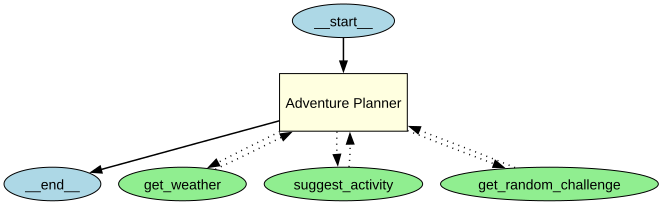

In [20]:
adventure_agent = Agent(
    name="Adventure Planner",
    instructions=(
        "You are a creative adventure planner. "
        "Always check current weather before recommending activities. "
        "Use suggest_activity for activity ideas. "
        "Use get_random_challenge to add a fun challenge. "
        "Give a short, practical plan."
    ),
    model=MODEL,
    tools=[weather_tool, suggest_activity, get_random_challenge],
)

draw_graph(adventure_agent)

The drawing shows one agent and three tools. Before you run the next cell: in which order will the three `TOOL CALLED` lines print,
and what will the agent pass to `suggest_activity`?

In [21]:
result = await Runner.run(
    adventure_agent,
    "I'm in Dubai. Plan a fun afternoon based on the current weather, and give me a challenge!",
)

print(result.final_output)

🌤️ TOOL CALLED: get_weather(Dubai)


🎯 TOOL CALLED: suggest_activity(Dubai, 28.7°C (feels like 32.1°C), dry with no rain and light wind around 6.9 km/h; currently 5 PM.)🎲 TOOL CALLED: get_random_challenge()



Dubai is **28.7°C but feels like 32°C**, with no rain and a light breeze. For a comfortable late afternoon:

- **Start with a swim** at a pool or beach you have access to; keep water handy.
- **Around sunset, take a short stroll** along the waterfront, then grab a cool drink indoors.

**Challenge:** Find the most unusual building nearby—and snap a photo of it.


Three `TOOL CALLED` lines: `get_weather(Dubai)` first, as the instructions asked, then `suggest_activity` and
`get_random_challenge()`. In our run the last two printed on one line: the model asked for both in the same reply,
and the runner ran them at the same time. Look at the start of the argument of `suggest_activity`: *Dubai, 28.7°C
(feels like 32.1°C), dry with no rain and light wind ...* It is the weather the first tool returned, put into words by the model.

**Key lesson:** we wrote no code that connects `get_weather` to `suggest_activity`. The model read the
instructions and the tool descriptions, called the weather tool first as asked, and wrote the next call's argument
from its result. Choosing the next
step from the results so far is what makes this an agent and not a script.

**Checkpoint D.** Three `TOOL CALLED` lines. `get_weather(Dubai)` comes first, and the argument of
`suggest_activity` describes the weather that call returned.

---

## Part E: Pass a question to a specialist with a handoff

One agent with three tools works well. One agent with thirty tools and a page of instructions starts choosing the
wrong tool. A common answer is to split the work: several small agents, each with its own instructions and tools,
and one agent at the front that decides who should take a question.

The SDK's word for passing a question on is a **handoff**. When agent A hands off to agent B, B takes over the
conversation: B reads everything so far, B uses its own tools, and B's answer is the run's answer.

We make two specialists. `handoff_description` is one sentence about each agent. The front agent reads it when it
decides where to send a question.

In [22]:
weather_specialist = Agent(
    name="Weather Specialist",
    handoff_description="Handles weather and temperature questions.",
    instructions="You are a weather specialist. Always check live weather with get_weather.",
    model=MODEL,
    tools=[weather_tool],
)

adventure_specialist = Agent(
    name="Adventure Specialist",
    handoff_description="Plans activities, outings and adventures.",
    instructions=(
        "You plan fun activities. Check the weather, use suggest_activity, "
        "and add a challenge when it fits."
    ),
    model=MODEL,
    tools=[weather_tool, suggest_activity, get_random_challenge],
)

The front agent has no tools of its own. It has `handoffs`: the agents it may pass a question to.

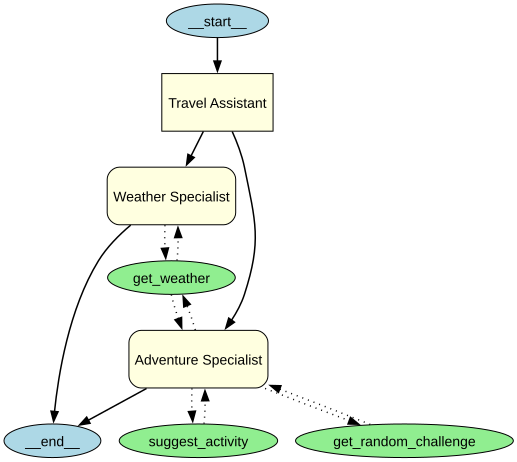

In [23]:
triage_agent = Agent(
    name="Travel Assistant",
    instructions=(
        "You are the main travel assistant. "
        "For weather questions, hand off to Weather Specialist. "
        "For travel plans or activities, hand off to Adventure Specialist. "
        "Do not answer specialist questions yourself."
    ),
    model=MODEL,
    handoffs=[weather_specialist, adventure_specialist],
)

draw_graph(triage_agent)

Compare this drawing with the one in Part D. The specialists are yellow boxes, because they are agents, each with
dotted arrows to its tools (the two share `get_weather`). The arrows from `Travel Assistant` to them are solid and point one way, and the arrows to `__end__`
leave from the specialists: once a specialist has the question, the run ends with its answer.

Two questions, one for each specialist. `result.last_agent` tells us who answered.

In [24]:
result = await Runner.run(triage_agent, "What's the temperature in Tokyo right now?")

print("Answered by:", result.last_agent.name)
print(result.final_output)

🌤️ TOOL CALLED: get_weather(Tokyo)


Answered by: Weather Specialist
It’s **8.1°C** in Tokyo right now (feels like **5.9°C**).


In [25]:
result = await Runner.run(triage_agent, "I'm visiting Barcelona. Suggest a fun afternoon!")

print("Answered by:", result.last_agent.name)
print(result.final_output)

🌤️ TOOL CALLED: get_weather(Barcelona)


🎯 TOOL CALLED: suggest_activity(Barcelona: 19.4°C, feels like 20.3°C, no precipitation, light wind at 7.1 km/h.)


🎲 TOOL CALLED: get_random_challenge()


Answered by: Adventure Specialist
Barcelona’s **mild, dry weather**—around **19°C** with a light breeze—sounds ideal for an outdoor afternoon.

Try a relaxed bike ride along the waterfront, then wander through **Parc de la Ciutadella** for a picnic or a rest in the shade. **Challenge:** find a local food you’ve never tried and make it your afternoon snack.


The Tokyo question was answered by `Weather Specialist`, with one `get_weather` call. The Barcelona question was
answered by `Adventure Specialist`, which called all three of its tools.

We started both runs at `Travel Assistant`, and a different agent finished each one. The handoff itself is in
`new_items`, next to the tool calls:

In [26]:
for item in result.new_items:
    if item.type == "handoff_output_item":
        print("handoff:", item.source_agent.name, "->", item.target_agent.name)
    elif item.type == "tool_call_item":
        print("tool call by", item.agent.name, ":", item.raw_item.name)

handoff: Travel Assistant -> Adventure Specialist
tool call by Adventure Specialist : get_weather
tool call by Adventure Specialist : suggest_activity
tool call by Adventure Specialist : get_random_challenge


For the Barcelona run: first the handoff, `Travel Assistant -> Adventure Specialist`, then three tool calls, all made
by the specialist. The only thing the front agent did was pass the question on.

**Important:** a handoff is one way. `Travel Assistant` does not get the conversation back, and it never sees the
specialist's answer. That is right for a question with one clear owner. Notebook 2 asks a question that needs two
specialists, and this is where a handoff goes wrong.

**Checkpoint E.** The Tokyo question is answered by `Weather Specialist`, the Barcelona question by
`Adventure Specialist`, and `new_items` shows the handoff before the specialist's tool calls.

---

## Part F: Use tools that run on OpenAI's side

Every tool so far ran in our own Python: we saw `TOOL CALLED` print on our machine. OpenAI also offers **hosted
tools**, which run on its servers. We name the tool, and the search, the reading and the indexing happen there.

| | Function tools (Parts A to E) | Hosted tools |
|---|---|---|
| Where the tool runs | our Python process | OpenAI's servers |
| Who writes it | we do | OpenAI |
| What we see | our own prints and return values | a record of the call in the result |
| Examples | `get_weather` | `WebSearchTool`, `FileSearchTool`, `CodeInterpreterTool` |

### Web search as a hosted tool

`WebSearchTool()` lets the model search the web and read pages. There is no function to write.

In [27]:
from agents import WebSearchTool

news_agent = Agent(
    name="Events Scout",
    instructions="You find things to do in a city. Search the web, answer in three short lines, and name your sources.",
    model=MODEL,
    tools=[WebSearchTool()],
)

result = await Runner.run(news_agent, "What is one event happening in Amman this month?")

print(result.final_output)

The 8th International Jordanian Dates Festival is happening **November 10–12** in Amman.  
It features different varieties of Jordanian dates.  
**Source:** Amman Chamber of Commerce. ([ammanchamber.org.jo](https://www.ammanchamber.org.jo/en/events/details/27253266/the-8th-international-jordanian-dates-festival))


No `TOOL CALLED` line: nothing ran on our machine. The record of what happened is in the result. For a hosted tool,
`raw_item.type` names the kind of call, and `result.context_wrapper.usage` holds the run's token counts.

In [28]:
for item in result.new_items:
    if item.type == "tool_call_item":
        print("hosted tool call:", item.raw_item.type)

usage = result.context_wrapper.usage
print("input tokens: ", usage.input_tokens)
print("output tokens:", usage.output_tokens)

hosted tool call: web_search_call
hosted tool call: web_search_call
input tokens:  10189
output tokens: 252


Two `web_search_call` items: two steps of searching and reading before the answer. The run used 10,189 input
tokens.

**Important:** the pages the search reads are put into the model's context, and we pay for them as input tokens.
OpenAI also charges a small fee for every search call. A web search is convenient, and it is not free.

### File search over our own document

Our own documents are not on the web. `FileSearchTool` searches files we upload, in two stages:

1. **Upload and index.** We create a **vector store** on OpenAI's side and upload a file to it. OpenAI reads the
   file, splits it into pieces and indexes them. (Labs 10 to 12 build this by hand; here it is one call.)
2. **Ask.** We give the agent a `FileSearchTool` that points at the store.

The file is a PDF in this repository, in the folder `21_AI_Governance_Document/`: a nine-page reference guide to AI
governance frameworks. `upload_and_poll` uploads it and waits until the indexing is finished.

In [29]:
GUIDE = ROOT / "21_AI_Governance_Document" / "AI_Governance_Frameworks_Reference_Guide.pdf"

vector_store = client.vector_stores.create(name="Lab 07 governance guide")

with open(GUIDE, "rb") as pdf:
    indexed = client.vector_stores.files.upload_and_poll(vector_store_id=vector_store.id, file=pdf)

print("vector store:", vector_store.id[:6] + "...")
print("file status: ", indexed.status)

vector store: vs_6af...
file status:  completed


In [30]:
from agents import FileSearchTool

guide_agent = Agent(
    name="Guide Assistant",
    instructions="Answer from the uploaded guide only. If the guide does not say, say so.",
    model=MODEL,
    tools=[FileSearchTool(vector_store_ids=[vector_store.id], max_num_results=5)],
)

result = await Runner.run(
    guide_agent,
    "Which references does the guide recommend as its reference stack, and what is each one for?",
)

print(result.final_output)
print()
print("hosted tools called:", [item.raw_item.type for item in result.new_items if item.type == "tool_call_item"])

The guide’s recommended **core reference stack** is:

- **NIST AI RMF** — provides the structure for AI risk management.
- **ISO/IEC 42001** — provides requirements for an organization-wide AI management system.
- **Databricks DAGF** — offers practical enterprise governance considerations and a checklist.
- **CSA AI Controls Matrix (AICM)** — supplies detailed security controls, evidence considerations, and material for vendor review.  

The guide recommends using **Microsoft, AWS, IBM, OECD, OWASP, and applicable laws as complementary references**, rather than substitutes for that core stack. Their roles include responsible-AI principles and policy language (OECD), operational examples (Microsoft), cloud and agent architecture practices (AWS), risk taxonomy and governance workflows (IBM), AI security threats and mitigations (OWASP), and binding obligations where applicable (relevant laws).   

hosted tools called: ['file_search_call']


The answer names the four references of the guide's recommended stack: NIST AI RMF for the risk structure, ISO/IEC
42001 for the management system, Databricks DAGF for practical enterprise considerations, and the CSA AI Controls
Matrix for detailed controls. Open the PDF at its second page and check them.

`hosted tools called` shows how the agent got there: one `file_search_call`. The model did not read the whole file.
The file search returned the pieces that matched the question, and the model answered from those.

### Two hosted tools in one agent

An analyst often needs both: what our own documents say, and what the web says. We give one agent both tools, then
look at which tools it called.

In [31]:
QUESTION_BOTH = "What does our guide say about the NIST AI RMF, and what is the latest news on its revision?"

research_agent = Agent(
    name="Governance Analyst",
    instructions=(
        "You help people with AI governance questions. "
        "Use the uploaded guide for what our own guide says. "
        "Use web search for recent developments. "
        "Answer in five lines or fewer."
    ),
    model=MODEL,
    tools=[WebSearchTool(), FileSearchTool(vector_store_ids=[vector_store.id], max_num_results=3)],
)

result = await Runner.run(research_agent, QUESTION_BOTH)

print(result.final_output)
print()
print("hosted tools called:", [item.raw_item.type for item in result.new_items if item.type == "tool_call_item"])

- **Our guide:** It recommends the voluntary NIST AI RMF as the foundation for enterprise AI risk governance—use its **Govern, Map, Measure, Manage** functions, with the Playbook for suggested actions and the Generative AI Profile for GenAI risks. 
- **Latest revision news (as of November 10, 2026):** NIST confirms AI RMF 1.0 is being revised under the White House AI Action Plan, but its current page gives no draft or release date. NIST’s latest related release is an **April 7, 2026 concept note** for a separate critical-infrastructure profile—not the revised framework itself. ([nist.gov](https://www.nist.gov/itl/ai-risk-management-framework))

hosted tools called: ['file_search_call', 'web_search_call', 'web_search_call']


`hosted tools called` lists a `file_search_call` and two `web_search_call` items. The answer keeps the two sources
apart: what our guide says about the NIST AI RMF (its four functions: Govern, Map, Measure, Manage), and what the
web says about the revision, with a link.

**Important:** the model decides whether to call a tool, hosted or not. In this run it called both. On another run,
or with another model, it may decide the guide is enough and skip the web. When an answer must use a tool, say so
plainly in the instructions (*Always search both the uploaded guide and the web before answering*), and check
`new_items` to see that it did.

### Delete what we stored

The vector store and the uploaded file stay in the OpenAI account until someone deletes them. Storage is
billed above a free allowance, and leftovers clutter the account. We remove both.

In [32]:
client.vector_stores.delete(vector_store.id)
client.files.delete(indexed.id)
print("vector store and file deleted")

vector store and file deleted


**Checkpoint F.** The web search answers with a source and prints no `TOOL CALLED` line; its hosted call shows as
`web_search_call`. The guide question is answered from the PDF through one `file_search_call`. The agent with both tools lists a
`file_search_call` and one or more `web_search_call` items. The last cell
confirms the store and the file are deleted.

---

## Part G (optional): Run the same agent on another vendor's model

The Agents SDK comes from OpenAI, and it is not tied to OpenAI's models. `LitellmModel` wraps
[LiteLLM](https://docs.litellm.ai/), a library that speaks to many providers through one interface. We pass it where
the model name went, and nothing else about the agent changes: same instructions, same `weather_tool`, same
`Runner.run`.

⚠️ This part needs a second key, `GEMINI_API_KEY`, in `.env`. It is optional: without the key the cell prints a
message and skips, and nothing in notebook 2 depends on it. The Gemini model name is `GEMINI_MODEL` in `models.env`.

In [33]:
GEMINI_KEY = os.environ.get("GEMINI_API_KEY") or local.get("GEMINI_API_KEY")

if not GEMINI_KEY:
    print("No GEMINI_API_KEY in .env: skipping this optional part.")
else:
    from agents.extensions.models.litellm_model import LitellmModel

    gemini_weather = Agent(
        name="Gemini Weather Agent",
        instructions=INSTRUCTIONS,
        model=LitellmModel(model="gemini/" + settings["GEMINI_MODEL"], api_key=GEMINI_KEY),
        tools=[weather_tool],
    )

    result = await Runner.run(gemini_weather, QUESTION)
    print(result.final_output)

🌤️ TOOL CALLED: get_weather(Amman)


It's currently 13°C in Amman, but with a slight breeze, it feels a bit cooler at 10.6°C. The skies are clear with no rain in sight! 

Should you go for a walk? Absolutely, just throw on a nice cozy jacket and enjoy the fresh air! 🧥✨


With the key in place, the saved run shows the same `TOOL CALLED` line and an answer in a different voice. The tool
ran in our Python exactly as before; a Gemini model wrote the request for it and the reply. The trace of this run
is on the OpenAI Traces page too, because tracing belongs to the SDK and not to the model.

---

## What you can do now

- Write the tool loop by hand on the Responses API, and name each step: the schema, the `function_call`, our code
  running the function, the `function_call_output` (Parts A and B).
- Build the same agent with `function_tool`, `Agent` and `Runner.run`, and read a run from `last_agent`,
  `raw_responses` and `new_items` (Part C).
- Give an agent several tools and explain how it chooses their order (Part D).
- Pass a question to a specialist with a handoff, and say who answered (Part E).
- Use web search and file search as hosted tools, see which ones a run called, and delete what you stored (Part F).
- Swap the model for another vendor's without changing the agent (Part G).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ExecutableNotFound: failed to execute PosixPath('dot'), make sure the Graphviz executables are on your systems' PATH` | `draw_graph` needs the Graphviz program, not only the Python package | install Graphviz (`sudo apt install -y graphviz` on Ubuntu, `brew install graphviz` on a Mac); every other cell works without it |
| `RuntimeError: AgentRunner.run_sync() cannot be called when an event loop is already running.` | `Runner.run_sync` starts its own event loop, and Jupyter already runs one | in a notebook, write `await Runner.run(...)` |
| `MaxTurnsExceeded: Max turns (1) exceeded` | the run reached `max_turns` before the model answered | raise `max_turns`, or find out why the model keeps asking for tools |
| `City not found: ...` in a tool result | Open-Meteo did not recognise the city name | ask with the city's common English name |

## Challenge

Give the adventure planner a budget tool.

1. Write a tool `estimate_budget(activity: str) -> str` that returns a made-up price range for an activity (for
   example a dictionary lookup with a default). Add it to a copy of `adventure_agent`, and add one line to the
   instructions saying when to use it.
2. Ask for a plan in a city of your choice. From `result.new_items`, print the tools in the order the model called
   them.

Expected: four `TOOL CALLED` lines, with `get_weather` first and `estimate_budget` after `suggest_activity`. Then
look at the argument the model wrote for `estimate_budget`: is it one of the names your tool expects?

The worked solution, run with its outputs, is in `solved/07a_meet_the_agents_sdk_solution.ipynb`.

## Resources

- [OpenAI Agents SDK](https://openai.github.io/openai-agents-python/): the documentation's home, with a quickstart
- [Tools](https://openai.github.io/openai-agents-python/tools/): `function_tool`, hosted tools, agents as tools
- [Running agents](https://openai.github.io/openai-agents-python/running_agents/): `Runner.run`, the agent loop,
  `max_turns`
- [Results](https://openai.github.io/openai-agents-python/results/): `final_output`, `new_items`, `raw_responses`,
  `last_agent`
- [Handoffs](https://openai.github.io/openai-agents-python/handoffs/): passing a conversation to another agent
- [Tracing](https://openai.github.io/openai-agents-python/tracing/): what a trace records and how to switch it off
- [Models](https://openai.github.io/openai-agents-python/models/): using other providers' models
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling) and
  [file search](https://developers.openai.com/api/docs/guides/tools-file-search): the API underneath
- [Open-Meteo](https://open-meteo.com/en/docs): the weather service `get_weather` calls

Next: [notebook 2, the Agents SDK at the Chinook desk](07b_agents_sdk_at_the_desk.ipynb).